In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay, precision_recall_curve)


In [20]:
df=pd.read_csv("../dataset/paylater_kaggle.csv")
df.head(10)

C:\Users\j4m4l\AppData\Local\Temp\ipykernel_20684\1483679511.py:1: DtypeWarning: Columns (0: loanId) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv("../dataset/paylater_kaggle.csv")


,loanId,clientIncome,incomeVerified,clientAge,clientGender,clientMaritalStatus,clientLoanPurpose,clientResidentialStatus,clientTimeAtEmployer,clientNumberPhoneContacts,...,paymentRatio,firstPaymentDefault,loanDefault,loanIncomeRatio,applicationDateMonth,approvalDateMonth,disbursementDateMonth,repaidDateMonth,FirstPaymentDueDateMonth,dueDateMonth
0,PP99804128,66452.66,1,38,MALE,Married,education,Employer Provided,> 36 Months,458.000000,...,0.0,0,0,0.632029,5,5,5,5,6,8
1,PP99781446,35000.00,1,35,MALE,Single,other,Rented,> 36 Months,708.000000,...,0.0,0,0,0.571429,5,5,5,6,6,8
2,PP99274960,162851.11,1,47,FEMALE,Married,education,Own Residence,> 36 Months,622.000000,...,0.0,1,0,0.822837,5,5,5,6,6,8
3,PP97847695,55053.68,1,33,MALE,Single,other,Own Residence,> 36 Months,1289.979347,...,0.0,0,1,0.626661,5,5,5,5,6,8
4,PP97841916,32112.55,1,30,MALE,Single,house,Rented,> 36 Months,608.000000,...,0.0,1,0,0.622809,5,5,5,6,6,8
5,PP96645536,46760.64,1,45,MALE,Married,medical,Rented,> 36 Months,608.000000,...,0.0,0,0,0.630872,5,5,5,5,6,8
6,PP96235226,37890.77,1,34,MALE,Single,house,Rented,27-35 Months,451.000000,...,0.0,1,0,0.527833,5,5,5,6,6,8
7,PP95837939,55328.67,1,36,MALE,Single,house,Rented,> 36 Months,446.000000,...,0.0,0,0,0.487993,5,5,5,5,6,7
8,PP94055953,33318.13,1,32,FEMALE,Married,medical,Rented,> 36 Months,644.000000,...,0.0,0,0,0.630287,4,4,4,5,5,7
9,PP93977426,57404.62,1,42,MALE,Married,house,Own Residence,> 36 Months,430.000000,...,0.0,0,1,0.627127,5,5,5,5,6,8


In [21]:
print(f"Ukuran data: ", df.shape)
df.info()

Ukuran data:  (159596, 28)
<class 'pandas.DataFrame'>
RangeIndex: 159596 entries, 0 to 159595
Data columns (total 28 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   loanId                     159596 non-null  object 
 1   clientIncome               159596 non-null  float64
 2   incomeVerified             159596 non-null  int64  
 3   clientAge                  159596 non-null  int64  
 4   clientGender               159596 non-null  str    
 5   clientMaritalStatus        159596 non-null  str    
 6   clientLoanPurpose          159596 non-null  str    
 7   clientResidentialStatus    159596 non-null  str    
 8   clientTimeAtEmployer       159596 non-null  str    
 9   clientNumberPhoneContacts  159596 non-null  float64
 10  clientAvgCallsPerDay       159596 non-null  float64
 11  loanNumber                 159596 non-null  int64  
 12  loanAmount                 159596 non-null  int64  
 13  interestRate 

## Eksplorasi Data (EDA)
Tujuan utama pengecekan kolom adalah untuk melihat apakah data Anda mengalami ketidakseimbangan kelas (class imbalance)—yang sangat umum terjadi pada kasus pendeteksian gagal bayar, di mana jumlah nasabah yang lancar (0) biasanya jauh lebih mendominasi dibandingkan nasabah yang gagal bayar (1).

In [22]:
print("Missing value per kolom")
print(df.isna().sum()[df.isna().sum()>0])
print()
print(df["loanDefault"].value_counts())
print(df["loanDefault"].value_counts(normalize=True).round(3))

Missing value per kolom
Series([], dtype: int64)

loanDefault
0    115321
1     44275
Name: count, dtype: int64
loanDefault
0    0.723
1    0.277
Name: proportion, dtype: float64


In [23]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
clientIncome,159596.0,90839.06,97280.33,30.00,35000.00,55116.21,105000.00,3925000.0
incomeVerified,159596.0,0.16,0.37,0.00,0.00,0.00,0.00,1.0
clientAge,159596.0,33.69,7.18,18.00,28.00,33.00,38.00,60.0
clientNumberPhoneContacts,159596.0,1262.06,1512.44,0.00,435.00,842.00,1532.00,60595.0
clientAvgCallsPerDay,159596.0,59.16,101.21,0.00,10.05,30.30,70.03,10994.5
loanNumber,159596.0,3.56,2.47,1.00,2.00,3.00,4.00,32.0
loanAmount,159596.0,35324.18,27840.82,11000.00,20000.00,25500.00,37500.00,500000.0
interestRate,159596.0,13.33,4.47,4.50,10.00,12.50,15.00,20.0
loanTerm,159596.0,85.39,39.32,60.00,60.00,60.00,90.00,180.0
maxAmountTaken,159596.0,0.71,0.46,0.00,0.00,1.00,1.00,1.0


Berdasarkan analisis statistik deskriptif di atas, kita dapat menyimpulkan bahwa dataset ini memiliki ukuran yang sangat memadai untuk melatih model machine learning dengan total hampir 160.000 baris data. Namun, terdapat beberapa catatan penting mengenai distribusi kelas target di mana sekitar 28% dari total nasabah mengalami gagal bayar (loanDefault), yang menunjukkan adanya ketidakseimbangan kelas (class imbalance) dan memerlukan perhatian khusus saat pemodelan nanti. Selain itu, ditemukan beberapa anomali data atau outlier ekstrem yang tidak wajar—seperti jumlah panggilan harian yang mencapai puluhan ribu serta nilai rasio pinjaman yang terlalu tinggi—sehingga proses pembersihan data (data cleaning) menjadi tahapan wajib sebelum data tersebut aman untuk diproses oleh algoritma.

data asli memang sering kali berantakan dan mengandung nilai-nilai ekstrem seperti itu. Meskipun data tersebut asli, bukan berarti data itu bisa langsung dimasukkan begitu saja ke dalam model machine learning.

In [24]:
max_calls_limit = df['clientAvgCallsPerDay'].quantile(0.99)
df['clientAvgCallsPerDay'] = df['clientAvgCallsPerDay'].clip(upper=max_calls_limit)

# Membatasi nilai rasio yang tidak masuk akal
max_ratio_limit = df['loanIncomeRatio'].quantile(0.99)
df['loanIncomeRatio'] = df['loanIncomeRatio'].clip(upper=max_ratio_limit)

# Menangani 'settleDays' (Nilai Negatif)
df['isEarlySettlement'] = df['settleDays'] < 0

print(df[['clientAvgCallsPerDay', 'loanIncomeRatio', 'settleDays']].describe().T.round(2))

                         count   mean    std    min    25%    50%    75%  \
clientAvgCallsPerDay  159596.0  56.53  76.14   0.00  10.05  30.30  70.03   
loanIncomeRatio       159596.0   0.67   0.56   0.01   0.29   0.51   0.91   
settleDays            159596.0  32.60  84.55 -32.00  -2.00   0.00  13.00   

                         max  
clientAvgCallsPerDay  444.03  
loanIncomeRatio         3.00  
settleDays            386.00  


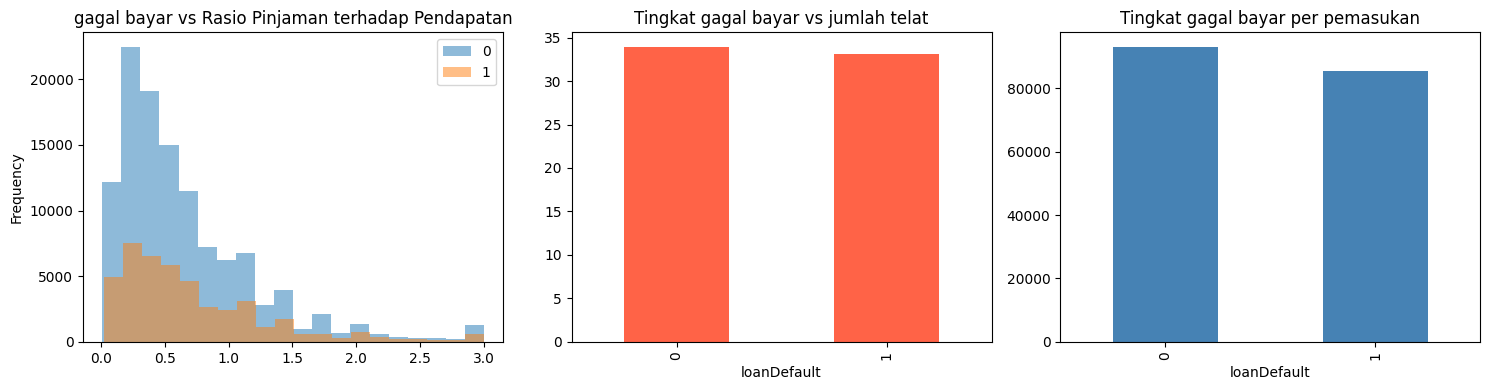

In [29]:
fig, ax = plt.subplots(1,3, figsize=(15, 4))
df.groupby("loanDefault")["loanIncomeRatio"].plot(kind="hist", alpha=0.5, bins=20, ax=ax[0], legend=True)
ax[0].set_title("gagal bayar vs Rasio Pinjaman terhadap Pendapatan")
df.groupby("loanDefault")["clientAge"].mean().plot(kind="bar", ax=ax[1], color="tomato")
ax[1].set_title(" gagal bayar vs umur")
df.groupby("loanDefault")["clientIncome"].mean().plot(kind="bar", ax=ax[2], color="steelblue")
ax[2].set_title(" gagal bayar per pemasukan")
plt.tight_layout(); plt.show()

## Preprocessing

In [31]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

target = "loanDefault"

x = df.drop(columns=[target, "loanId"])
y = df[target]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", x_train.shape, "Test :", x_test.shape)
print("Rasio gagal bayar train", round(y_test.mean(), 3),"| test", round(y_test.mean(),3))

Train: (127676, 27) Test : (31920, 27)
Rasio gagal bayar train 0.277 | test 0.277


In [32]:
fitur_num = x.select_dtypes(include="number").columns.to_list()
fitur_kat = x.select_dtypes(include="number").columns.to_list()
print("Numerik:", fitur_num)
print("Katergori:", fitur_kat)

prep_linear = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy = "most_frequent")),
                    ("sc", StandardScaler())]), fitur_num),
    ("kat", Pipeline([("imp", SimpleImputer(strategy = "most_frequent")),
                    ("ohe", OneHotEncoder(handle_unknown="ignore"))]), fitur_kat),
])

Numerik: ['clientIncome', 'incomeVerified', 'clientAge', 'clientNumberPhoneContacts', 'clientAvgCallsPerDay', 'loanNumber', 'loanAmount', 'interestRate', 'loanTerm', 'maxAmountTaken', 'maxTenorTaken', 'settleDays', 'paymentRatio', 'firstPaymentDefault', 'loanIncomeRatio', 'applicationDateMonth', 'approvalDateMonth', 'disbursementDateMonth', 'FirstPaymentDueDateMonth', 'dueDateMonth']
Katergori: ['clientIncome', 'incomeVerified', 'clientAge', 'clientNumberPhoneContacts', 'clientAvgCallsPerDay', 'loanNumber', 'loanAmount', 'interestRate', 'loanTerm', 'maxAmountTaken', 'maxTenorTaken', 'settleDays', 'paymentRatio', 'firstPaymentDefault', 'loanIncomeRatio', 'applicationDateMonth', 'approvalDateMonth', 'disbursementDateMonth', 'FirstPaymentDueDateMonth', 'dueDateMonth']


In [35]:
model_lr = Pipeline([("prep", prep_linear),
                    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

model_lr.fit(x_train, y_train)

pred_lr = model_lr.predict(x_test)
proba_lr = model_lr.predict_proba(x_test)[:,1]

print("Acurracy:", round(accuracy_score(y_test, pred_lr), 3))
print("ROC_AUC:", round(roc_auc_score(y_test, pred_lr), 3))

Acurracy: 0.873
ROC_AUC: 0.799


## Evaluasi Model

In [37]:
def evaluasi(nama, model, X_test, y_test, threshold=0.5):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"model": nama,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred),
            "roc_auc": roc_auc_score(y_test, proba)}

hasil = [evaluasi("Logistic Regression", model_lr, x_test, y_test)]
pd.DataFrame(hasil).round(3)

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.873,0.873,0.633,0.734,0.899


              precision    recall  f1-score   support

      Lancar       0.87      0.96      0.92     23065
 Gagal bayar       0.87      0.63      0.73      8855

    accuracy                           0.87     31920
   macro avg       0.87      0.80      0.82     31920
weighted avg       0.87      0.87      0.87     31920



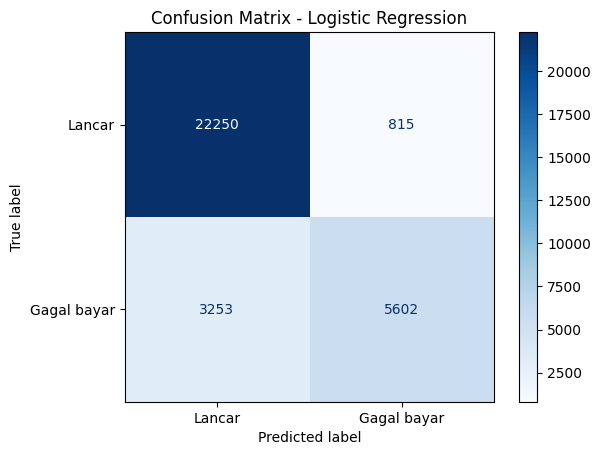

In [38]:
print(classification_report(y_test, pred_lr, target_names=["Lancar", "Gagal bayar"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, pred_lr, display_labels=["Lancar", "Gagal bayar"], cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression"); plt.show()